# Training the HyPER decision model with REINFORCE

This notebook walks through how we train the **RL actor** at the heart of HyPER
("Hybrid PDE Predictor with Reinforcement Learning", [arXiv:2503.10048](https://arxiv.org/abs/2503.10048))
on the clean Navier-Stokes smoke-plume dataset (`data/ns_data_64_1000.h5`).

HyPER pairs a fast neural **surrogate** with an expensive physics **simulator**. During an
autoregressive rollout, a learned *actor* decides at each step whether to trust the surrogate
or to pay for a simulator correction. The surrogate and simulator are **fixed** here — the only
thing we train is the actor's policy, and we train it with the **REINFORCE** policy-gradient
algorithm.

**What this notebook covers**
1. Load the frozen surrogate and simulator, and a freshly-initialized actor.
2. Explain the REINFORCE objective and the HyPER reward function.
3. Train the actor for a few epochs on a small subset of the RL split.
4. Plot reward, advantage, policy loss, and simulator usage over training.
5. Save the trained actor checkpoint.

> This is a *reduced* demo run (32 trajectories × 6 epochs) so it finishes in minutes on a single
> GPU. The full paper configuration (`src/train_rl_reinforce_ns.py`) trains on all 400 RL-split
> trajectories for 30 epochs; the code here is a faithful, notebook-friendly port of it.

In [1]:
import sys
import math
import warnings
from collections import deque
from dataclasses import dataclass

import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
from tqdm import tqdm

import torch
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, Subset, random_split
from torch.distributions import Bernoulli

if ".." not in sys.path:
    sys.path.insert(0, "..")  # make src/ importable (utils, models, data)

%matplotlib inline
plt.rcParams["figure.dpi"] = 300.0

# The phiflow simulator runs an eager, singular pressure solve on every correction
# step (see section 3). It emits a few known-benign rank-deficiency / sparse-tensor
# warnings per call; we silence them so the training log below stays readable.
warnings.filterwarnings("ignore", message=".*Rank deficiency.*")
warnings.filterwarnings("ignore", message=".*Sparse.*")
warnings.filterwarnings("ignore", message=".*spsolve requires.*")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 1. The three HyPER components

Training the actor requires three pieces:

| Component | Role in training | Trained here? |
|-----------|------------------|:-------------:|
| **Surrogate** (U-Net, time-conditioned) | the cheap predictor the actor can choose at each step | ❌ frozen |
| **Simulator** (phiflow Navier-Stokes solver) | the expensive correction the actor can choose instead | ❌ fixed |
| **Actor** (ResNet-18, Bernoulli policy) | decides surrogate-vs-simulator per step | ✅ **trained** |

We load the pretrained `unet-400` surrogate (trained on 400 trajectories) exactly as in the
inference tutorial, and we create a **fresh, randomly-initialized** actor — this is the policy
REINFORCE will learn. The actor is a `resnet18_cond` that outputs `S=4` Bernoulli logits per call,
i.e. one surrogate-vs-simulator decision for each step of a 4-step window.

In [2]:
# --- Load the frozen surrogate and a fresh actor ---
import utils
from models.twod_unet_cond import Unet as UnetCond
from models.resnet import resnet18_cond

ckpt_dir = "../../model_checkpoints"
S = 4  # actor decision-window length == actor num_classes

# Frozen neural surrogate: time-conditioned 2D U-Net, 1-channel smoke field.
def build_surrogate():
    return UnetCond(1, 0, 1, 0, 1, 1, 64, "gelu",
                    ch_mults=[1, 2, 2], is_attn=[False, False, False])

surrogate = utils.load_model(
    f"{ckpt_dir}/unet-400-lr-0.0001-bs-8-epochs-200-1_model_checkpoint_199_final.pt",
    build_surrogate()).to(device)
surrogate.eval()
for p in surrogate.parameters():
    p.requires_grad_(False)  # the surrogate is never updated during RL training

# Fresh actor / decision model: ResNet-18 emitting S Bernoulli logits per call.
# This is the policy we train. (In the inference tutorial we instead LOADED a
# pretrained actor; here we start from random init.)
torch.manual_seed(42)
actor = resnet18_cond(num_classes=S, param_conditioning=False).to(device)

print(f"surrogate (frozen): {sum(p.numel() for p in surrogate.parameters()):,} params")
print(f"actor     (train) : {sum(p.numel() for p in actor.parameters()):,} params")

surrogate (frozen): 12,295,233 params
actor     (train) : 11,751,300 params


## 2. The dataset and the RL split

We use the same 1000-trajectory Navier-Stokes dataset and the same seed-42
`40/40/10/10` split as the inference tutorial — but training the actor uses the **second**
split (the *RL split*), which is held out from the surrogate's training data. The actor learns
its policy on fresh trajectories the surrogate has never seen.

We request velocity fields too, because the simulator needs them for its corrections.
For this demo we take the first **32** trajectories of the RL split and train with `batch_size=1`
(the rollout and phiflow simulator operate one trajectory at a time).

In [3]:
# --- Load the dataset and build the RL-split subset ---
from data.navier_stokes_dataset import NavierStokesDataset

dataset_path = "../../data/ns_data_64_1000.h5"
dataset_split = (0.40, 0.40, 0.10, 0.10)  # train, RL, val, test
random_seed = 42

# Rollout window: predict timesteps ST..FT-1 autoregressively from the state at ST-1.
ST, FT = 8, 28
T = FT - ST  # number of rollout steps (20)

# Dataset statistics used to standardize the smoke field (from training).
smoke_mean = 0.7322910149367649
smoke_std = 0.43668617344401106

# Demo scale: a small subset of the RL split so the notebook runs in minutes.
N_TRAJ = 32

dataset = NavierStokesDataset(dataset_path, provide_velocity=True)
train_dataset, rl_dataset, val_dataset, test_dataset = random_split(
    dataset, dataset_split, generator=torch.Generator().manual_seed(random_seed))

rl_subset = Subset(rl_dataset, list(range(N_TRAJ)))
rl_dataloader = DataLoader(rl_subset, batch_size=1, shuffle=False, pin_memory=True)

print(f"RL split size      : {len(rl_dataset)} trajectories")
print(f"Demo subset        : {len(rl_subset)} trajectories")
print(f"Rollout window     : t={ST}..{FT - 1} ({T} steps) in {T // S} windows of S={S}")

RL split size      : 400 trajectories
Demo subset        : 32 trajectories
Rollout window     : t=8..27 (20 steps) in 5 windows of S=4


## 3. The phiflow simulator (the correction the actor can call)

When the actor chooses to **correct** a step, HyPER advances the state with a real
incompressible Navier-Stokes solver instead of the surrogate: advect smoke → apply buoyancy →
advect + diffuse velocity → project to divergence-free. This is identical to the simulator in the
inference tutorial and is ported verbatim from `train_rl_reinforce_ns.py`, so the physics the actor
is trained against matches exactly.

In [4]:
# --- The phiflow physics simulator + torch<->phiflow converters ---
from phi.torch.flow import (Box, CenteredGrid, StaggeredGrid, Solve, advect, diffuse,
                            extrapolation, fluid, spatial, channel)
from phi.math import tensor as phi_tensor
from phiml.math import Diverged, NotConverged

# Simulator parameters (from the RL training config).
dt = 96.0 / 64.0          # timestep duration (seconds)
buoyancy_factor = 0.5     # upward buoyancy applied to the smoke field
diffusion_coef = 0.01     # velocity diffusion coefficient


def torch_to_phi_centered(data):
    # smoke: (H, W) torch -> phiflow CenteredGrid on a 32x32 domain
    phi_ten = phi_tensor(data.transpose(1, 0), spatial('x,y'))  # transpose so x,y land in the right dims
    phi_grid = CenteredGrid(phi_ten, extrapolation.BOUNDARY, Box['x,y', 0:32.0, 0:32.0])
    return phi_grid


def phi_centered_to_torch(data):
    data_np = data.values.numpy('x,y')
    return torch.from_numpy(data_np.transpose(1, 0))  # back to (y, x) order


def torch_to_phi_staggered(data_x, data_y):
    # velocity components: (H, W) torch -> phiflow StaggeredGrid.
    # Staggered grids store one extra sample per dim, so we pad by replicating the edge.
    data_x = torch.cat((data_x, data_x[:, -1].reshape(data_x.shape[1], -1)), 1)
    data_x = torch.cat((data_x, data_x[-1, :].reshape(-1, data_x.shape[1])), 0)
    data_y = torch.cat((data_y, data_y[:, -1].reshape(data_y.shape[1], -1)), 1)
    data_y = torch.cat((data_y, data_y[-1, :].reshape(-1, data_y.shape[1])), 0)
    stacked = torch.stack((data_x.transpose(1, 0), data_y.transpose(1, 0)), dim=2)
    stacked_ten = phi_tensor(stacked, spatial('x,y'), channel('vector'))
    phi_grid = StaggeredGrid(stacked_ten, extrapolation.ZERO, Box['x,y', 0:32.0, 0:32.0])
    return phi_grid


def phi_staggered_to_torch(data):
    field = data.staggered_tensor().numpy('x,y,vector')
    field_x = torch.from_numpy(field[:-1, :-1, 0].transpose(1, 0))  # drop the extra staggered row/col
    field_y = torch.from_numpy(field[:-1, :-1, 1].transpose(1, 0))
    return field_x, field_y


def call_sim(smoke_grid, velocity_grid, dt, buoyancy_factor, diffusion_coef):
    # One incompressible Navier-Stokes step (run eager -- see the inference tutorial
    # for why we avoid phiflow's @jit_compile with the direct pressure solver).
    smoke_grid = advect.semi_lagrangian(smoke_grid, velocity_grid, dt)               # transport smoke
    buoyancy_force = (smoke_grid * (0, buoyancy_factor)).at(velocity_grid)            # smoke -> upward force
    velocity_grid = advect.semi_lagrangian(velocity_grid, velocity_grid, dt) + dt * buoyancy_force
    velocity_grid = diffuse.explicit(velocity_grid, diffusion_coef, dt)              # viscosity
    # Pressure projection to divergence-free. With closed boundaries the Poisson
    # system is singular (pressure defined up to a constant) so the residual floors
    # around 1e-3; the direct solver ("auto") still returns the correct projection
    # and we `suppress` the unreachable-tolerance exception.
    velocity_grid, _ = fluid.make_incompressible(
        velocity_grid,
        solve=Solve("auto", rel_tol=1e-5, abs_tol=1e-5, max_iterations=10000,
                    suppress=[Diverged, NotConverged]))
    return smoke_grid, velocity_grid


print("phiflow simulator ready.")
print(f"  dt={dt:.3f}s  buoyancy_factor={buoyancy_factor}  diffusion_coef={diffusion_coef}")

phiflow simulator ready.
  dt=1.500s  buoyancy_factor=0.5  diffusion_coef=0.01


## 4. REINFORCE and the HyPER reward

### The policy
At the start of each 4-step window the actor sees the current prediction stacked with the initial
state (plus a time embedding) and outputs logits. We squash them to probabilities and treat each as
an independent **Bernoulli** decision:

$$p_t = \sigma(\text{actor}(s_t)), \qquad a_t \sim \text{Bernoulli}(p_t), \qquad a_t \in \{0,1\}$$

where $a_t = 0$ means *use the surrogate* and $a_t = 1$ means *call the simulator* at step $t$.

### The reward
HyPER wants accurate rollouts, so the per-step reward is simply the **negative MSE** of the
chosen prediction against the ground-truth smoke field (in normalized units):

$$r_t = -\,\text{MSE}\big(\hat{x}_t,\; x_t\big)$$

Lower error ⇒ higher reward. The simulator is usually more accurate than the surrogate, so the
actor is nudged toward calling it — but the simulator is *expensive*, which the cost term handles below.

### The REINFORCE objective
REINFORCE ([Williams, 1992](https://doi.org/10.1007/BF00992696)) is the vanilla policy-gradient
method. For a trajectory of actions with log-probabilities $\log \pi(a_t)$ and returns $G_t$
(here the undiscounted sum of future rewards), it maximizes expected return by ascending

$$\nabla_\theta J = \mathbb{E}\!\left[\sum_t G_t\, \nabla_\theta \log \pi_\theta(a_t)\right]
\quad\Longrightarrow\quad
\mathcal{L} = -\sum_t G_t\,\log \pi_\theta(a_t).$$

Intuitively: actions that led to high return get their probability pushed **up**; low-return actions
get pushed **down**.

### Baseline (variance reduction)
Raw returns are noisy, so we subtract a **baseline** — a reference rollout that makes the *same number*
of simulator calls as the policy did, but at **randomly chosen** steps. Subtracting its reward turns the
return into an **advantage**: "did the actor place its simulator calls *better than random*?"

$$A_t = r_t - r_t^{\text{baseline}}$$

### Cost penalty (budget control)
Finally we discourage over-using the simulator with a penalty that pulls simulator usage toward a
target fraction $\lambda$ (here $\lambda = 0.3$, i.e. ~30% of steps):

$$A_t \leftarrow A_t - \big|\,\text{percent\_sim} - \lambda\,\big|$$

The three ideas — negative-MSE reward, random-placement baseline, and the $\lambda$ cost penalty —
are exactly what `train_rl_reinforce_ns.py` implements. The next cell ports them into two helpers.

In [5]:
# --- Training configuration ---
# Mirrors the tyro dataclass in train_rl_reinforce_ns.py, trimmed to a demo scale.
@dataclass(frozen=True)
class TrainConfig:
    learning_rate: float = 1e-5   # Adam LR for the actor
    epochs: int = 6               # demo: a few passes over the subset (paper uses 30)
    lam: float = 0.30             # target fraction of steps that call the simulator
    S: int = 4                    # actor decision-window length
    ST: int = 8                   # rollout start timestep
    FT: int = 28                  # rollout end timestep (exclusive)

config = TrainConfig()
print(config)

TrainConfig(learning_rate=1e-05, epochs=6, lam=0.3, S=4, ST=8, FT=28)


In [6]:
# --- Rollout helpers (faithful port of train_rl_reinforce_ns.py) ---

def call_model(timestep, last_pred, model, dev):
    """One surrogate step. last_pred is B x 1 x 1 x H x W (normalized)."""
    timesteps = torch.full((last_pred.shape[0],), timestep, device=dev)
    return model(last_pred, timesteps)


def sim_step(last_pred, velocity_x, velocity_y, t, smoke_template, dev):
    """One simulator correction step. Returns the normalized smoke prediction.

    last_pred : B x 1 x 1 x H x W normalized smoke; velocity_* : B x T x 1 x H x W (ground truth).
    smoke_template is used only to allocate the output buffer on cpu (matches the training code).
    """
    sim_output_smoke = torch.zeros_like(smoke_template[:, 0, ...], device='cpu')
    last_pred_unnorm = (last_pred.detach() * smoke_std + smoke_mean).clone()
    smoke_grid = torch_to_phi_centered(last_pred_unnorm.squeeze())
    velocity_grid = torch_to_phi_staggered(velocity_x[:, t - 1].squeeze(), velocity_y[:, t - 1].squeeze())
    smoke_grid, velocity_grid = call_sim(smoke_grid, velocity_grid, dt, buoyancy_factor, diffusion_coef)
    sim_output_smoke[:, ...] = phi_centered_to_torch(smoke_grid)
    sim_output_smoke = sim_output_smoke.to(dev)
    sim_output_smoke = (sim_output_smoke - smoke_mean) / smoke_std
    return sim_output_smoke


def policy_rollout(batch, actor, surrogate, config, dev):
    """Sample a HyPER rollout under the current policy.

    Returns the per-step log-probs (with grad), rewards, and the number of simulator calls.
    """
    ST, FT, Sw = config.ST, config.FT, config.S
    T = FT - ST
    smoke = batch["smoke"].unsqueeze(2).to(dev)         # B, T, 1, H, W
    velocity_x = batch["velocity_x"].unsqueeze(2).to(dev)
    velocity_y = batch["velocity_y"].unsqueeze(2).to(dev)
    smoke_norm = (smoke - smoke_mean) / smoke_std

    last_pred = smoke_norm[:, ST - 1, :, :, :].unsqueeze(1)    # seed with true state at ST-1
    init_state = smoke_norm[:, ST - 1, :, :, :].unsqueeze(1)

    log_probs, rewards = [], []
    num_sim_calls = 0
    start_time = ST
    for _ in range(T // Sw):
        rl_input = torch.cat((last_pred.squeeze(1), init_state.squeeze(1)), dim=1)   # B, 2, H, W
        time_tensor = torch.full((rl_input.shape[0],), start_time - 1, device=dev)
        rl_probs = torch.sigmoid(actor(rl_input, time_tensor))
        rl_dist = Bernoulli(probs=rl_probs.squeeze())
        rl_action = rl_dist.sample()
        log_probs.append(rl_dist.log_prob(rl_action))        # keep grad through log_prob

        for t in range(start_time, start_time + Sw):
            if rl_action[t - start_time] == 0:               # --- surrogate ---
                model_inputs = last_pred
                while model_inputs.dim() < 5:
                    model_inputs = model_inputs.unsqueeze(0)
                output = call_model(t, model_inputs, surrogate, dev)
                mse = F.mse_loss(output, smoke_norm[:, t, :, :, :].unsqueeze(1)).item()
                last_pred = output.detach()
            else:                                            # --- simulator correction ---
                num_sim_calls += 1
                sim_out = sim_step(last_pred, velocity_x, velocity_y, t, smoke, dev)
                mse = F.mse_loss(sim_out, smoke_norm[:, t, ...]).item()
                last_pred = sim_out.unsqueeze(1).detach()
            rewards.append(-mse)                             # reward = -MSE
        start_time += Sw

    log_probs = torch.cat(log_probs, 0)
    return log_probs, rewards, num_sim_calls


@torch.no_grad()
def baseline_rollout(batch, surrogate, config, num_sim_calls, dev):
    """Reference rollout for variance reduction: same number of simulator calls as the
    policy, but placed at RANDOM steps. Returns its per-step rewards."""
    ST, FT = config.ST, config.FT
    smoke = batch["smoke"].unsqueeze(2).to(dev)
    velocity_x = batch["velocity_x"].unsqueeze(2).to(dev)
    velocity_y = batch["velocity_y"].unsqueeze(2).to(dev)
    smoke_norm = (smoke - smoke_mean) / smoke_std

    last_pred = smoke_norm[:, ST - 1, :, :, :].unsqueeze(1)
    sim_call_choices = np.random.default_rng().choice(
        range(ST, FT), int(num_sim_calls), replace=False)

    baseline_rewards = []
    for t in range(ST, FT):
        if t not in sim_call_choices:                        # --- surrogate ---
            output = call_model(t, last_pred, surrogate, dev)
            mse = F.mse_loss(output, smoke_norm[:, t, :, :, :].unsqueeze(1)).item()
            last_pred = output.detach()
        else:                                                # --- simulator ---
            sim_out = sim_step(last_pred, velocity_x, velocity_y, t, smoke, dev)
            mse = F.mse_loss(sim_out, smoke_norm[:, t, ...]).item()
            last_pred = sim_out.unsqueeze(1).detach()
        baseline_rewards.append(-mse)
    return baseline_rewards


print("policy_rollout, baseline_rollout, sim_step defined.")

policy_rollout, baseline_rollout, sim_step defined.


## 5. The training loop

For each trajectory we:
1. **Sample** a rollout under the current policy → log-probs + rewards (`policy_rollout`).
2. Run the **baseline** rollout with the same simulator budget placed randomly → advantage
   `A_t = r_t − r_t^baseline` (`baseline_rollout`).
3. Apply the **cost penalty** `A_t ← A_t − |percent_sim − λ|`.
4. Accumulate undiscounted **returns** `G_t = Σ_{t'≥t} A_{t'}` and form the REINFORCE loss
   `L = −Σ_t G_t · log π(a_t)`.
5. Backprop and step Adam on the **actor only**.

We log reward, advantage, policy loss, and simulator-usage fraction each epoch so we can watch
the policy learn. (One epoch = one pass over all 32 demo trajectories; expect a few minutes per
epoch because every simulator call runs the eager phiflow solver.)

In [7]:
# --- Train the actor with REINFORCE ---
actor_optimizer = Adam(actor.parameters(), lr=config.learning_rate)
T = config.FT - config.ST

# Per-epoch metric history (for the plots below).
history = {"reward": [], "advantage": [], "policy_loss": [], "percent_sim": []}

actor.train()
for epoch in range(config.epochs):
    epoch_reward = epoch_advantage = epoch_policy_loss = percent_sim_epoch = 0.0

    for batch in tqdm(rl_dataloader, desc=f"Epoch {epoch}", unit="traj", leave=False):
        # 1. Sample a rollout under the current policy.
        log_probs, rewards, num_sim_calls = policy_rollout(batch, actor, surrogate, config, device)
        percent_sim = num_sim_calls / T

        # 2. Baseline rollout (same sim budget, random placement) -> advantage.
        baseline_rewards = baseline_rollout(batch, surrogate, config, num_sim_calls, device)
        advantages = [r - br for r, br in zip(rewards, baseline_rewards)]

        # 3. Cost penalty: pull simulator usage toward lambda.
        penalized = [a - np.abs(percent_sim - config.lam) for a in advantages]

        # 4. Undiscounted returns G_t = sum_{t'>=t} penalized_{t'}.
        returns = deque(maxlen=T)
        for t in range(T)[::-1]:
            running = returns[0] if len(returns) > 0 else 0.0
            returns.appendleft(running + penalized[t])
        returns = torch.tensor(returns)

        # REINFORCE loss: L = -sum_t G_t * log pi(a_t).
        assert len(log_probs) == len(returns)
        policy_loss = sum(-lp * G for lp, G in zip(log_probs, returns))

        # 5. Update the actor (surrogate stays frozen).
        actor_optimizer.zero_grad()
        policy_loss.backward()
        actor_optimizer.step()

        epoch_reward += sum(penalized)
        epoch_advantage += sum(advantages)
        epoch_policy_loss += policy_loss.item()
        percent_sim_epoch += percent_sim

    n = len(rl_dataloader)
    history["reward"].append(epoch_reward / n)
    history["advantage"].append(epoch_advantage / n)
    history["policy_loss"].append(epoch_policy_loss / n)
    history["percent_sim"].append(percent_sim_epoch / n)
    print(f"Epoch {epoch}: reward={history['reward'][-1]:+.4f}  "
          f"advantage={history['advantage'][-1]:+.4f}  "
          f"policy_loss={history['policy_loss'][-1]:+.4f}  "
          f"sim_usage={history['percent_sim'][-1]:.1%}")

print("Training complete.")

Epoch 0:   0%|                                                                                                                        | 0/32 [00:00<?, ?traj/s]/usr/projects/t24_multiscale_sft/bharats/aaai-symposium-hyper-tutorial/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
                                                                                                                                                               

Epoch 0: reward=-3.2377  advantage=+0.0436  policy_loss=-22.7642  sim_usage=46.4%


Epoch 1: reward=-3.4701  advantage=+0.0299  policy_loss=-24.3371  sim_usage=47.5%


Epoch 2: reward=-3.2740  advantage=-0.0240  policy_loss=-22.2579  sim_usage=46.2%


Epoch 3: reward=-2.6616  advantage=+0.0259  policy_loss=-18.1378  sim_usage=42.2%


Epoch 4: reward=-2.4059  advantage=-0.0309  policy_loss=-15.9665  sim_usage=39.7%


Epoch 5: reward=-2.6787  advantage=+0.0088  policy_loss=-18.6592  sim_usage=43.1%
Training complete.


## 6. Reward and training signals over time

**Reward** (penalized): the objective the policy maximizes — should trend **up**.

With only 32 trajectories × 6 epochs this curve is noisy.

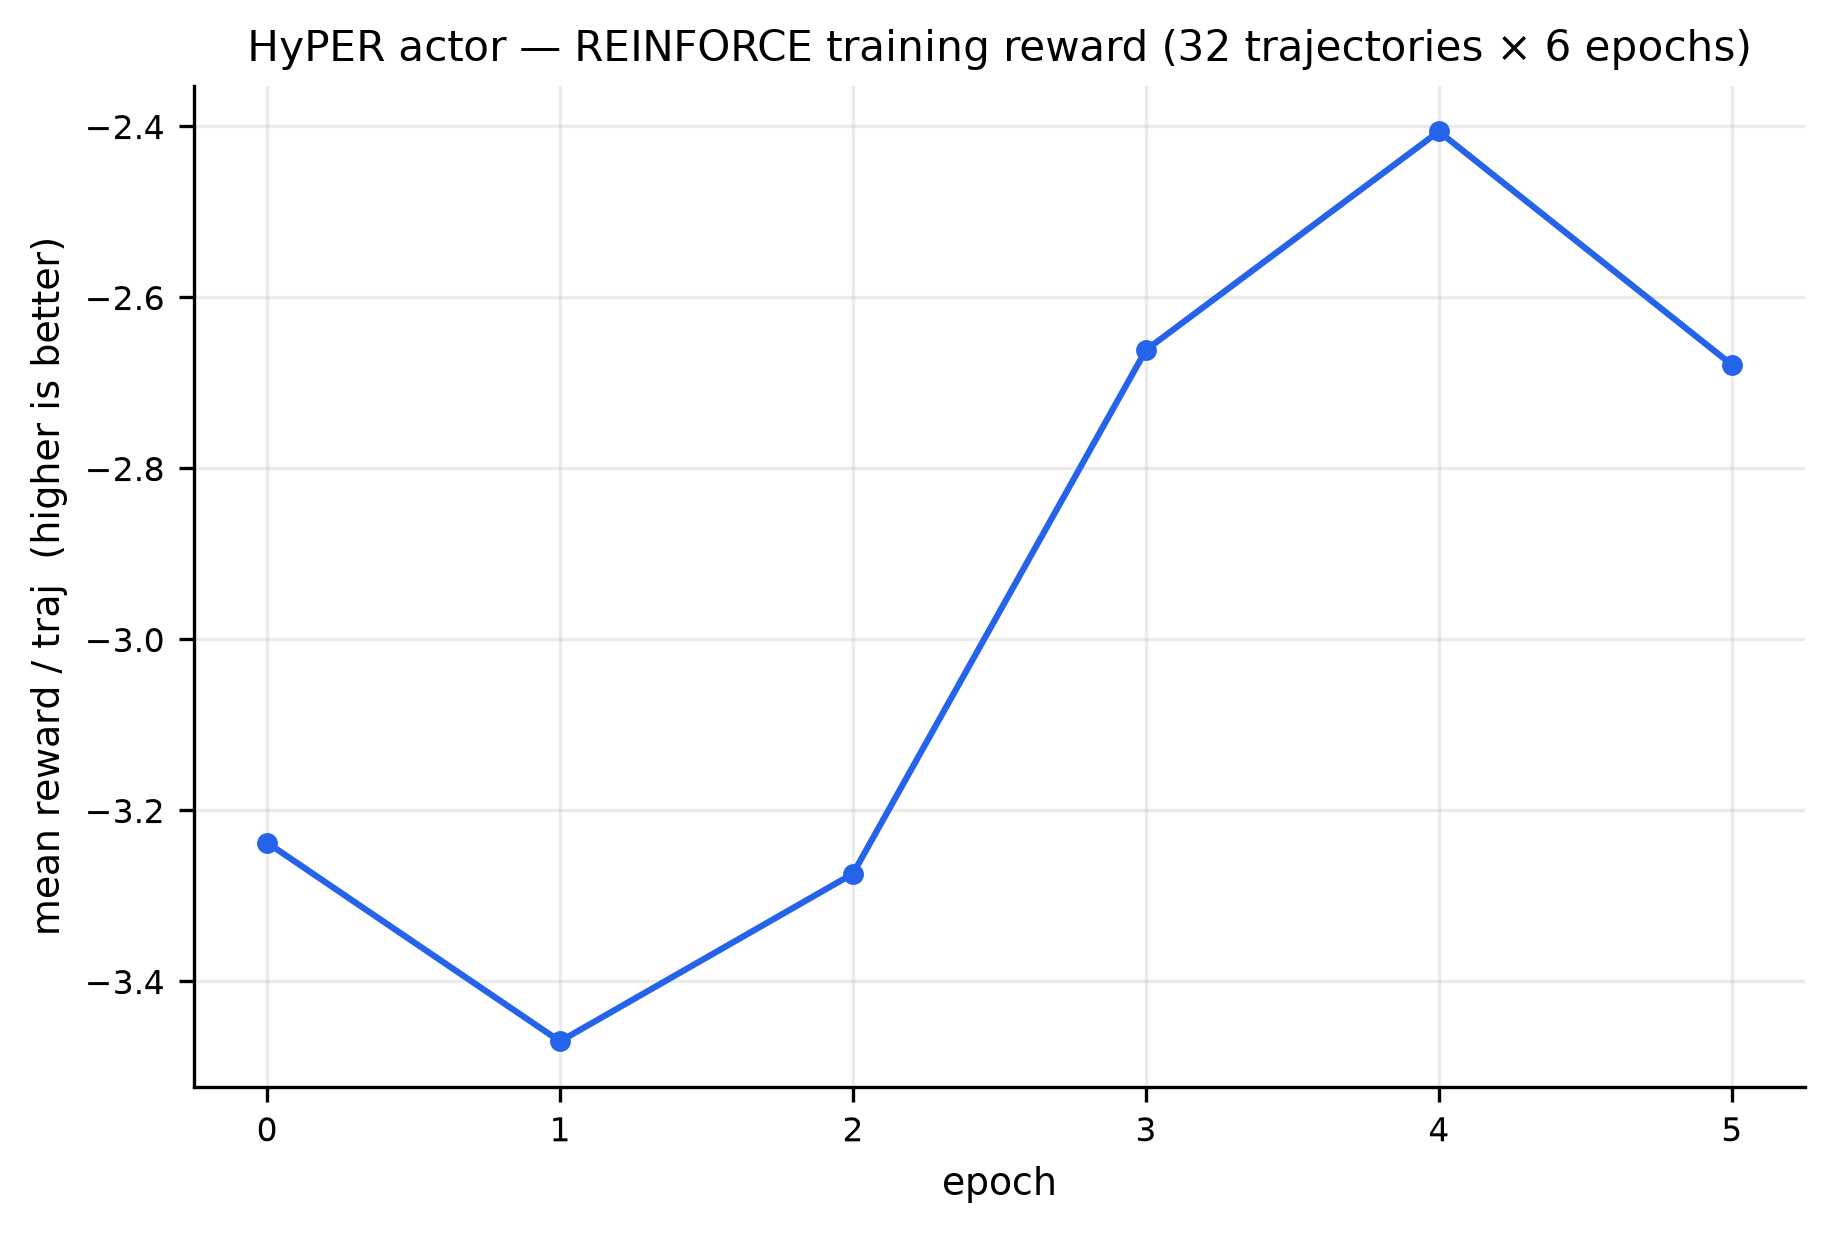

In [10]:
# --- Plot the training curve ---
C_HYPER = "#2563eb"   # blue, consistent with the inference tutorial
epochs = np.arange(config.epochs)

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(epochs, history["reward"], "-o", color=C_HYPER, lw=1.5, ms=4)
ax.set_title("HyPER actor — REINFORCE training reward (32 trajectories × 6 epochs)", fontsize=10)
ax.set_xlabel("epoch", fontsize=9)
ax.set_ylabel("mean reward / traj  (higher is better)", fontsize=9)
ax.grid(alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=8)
plt.show()

## 7. Save the trained actor

Finally we persist the trained actor to a demo output directory using the same
`utils.save_model_checkpoint` helper the training script uses. The checkpoint is a `.pt` file
containing the epoch, device, model `state_dict`, and optimizer `state_dict` — the same format the
inference notebook loads pretrained actors from.

In [11]:
# --- Save the trained actor checkpoint + training history ---
import json
from pathlib import Path

output_dir = Path("./rl_training_demo_output")
output_dir.mkdir(parents=True, exist_ok=True)

job_name = f"tutorial-actor-reinforce-lam-{config.lam}-S{config.S}-ns-64"
utils.save_model_checkpoint(
    epoch=config.epochs - 1,
    device=str(device),
    model=actor,
    optimizer=actor_optimizer,
    output_dir=output_dir,
    prefix=job_name,
    suffix="final",
    overwrite=True,
)

# Save the per-epoch metric history so the plots can be regenerated without retraining.
# Reload with:  history = json.load(open("./rl_training_demo_output/<job_name>_history.json"))
history_path = output_dir / f"{job_name}_history.json"
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)
print(f"Saved training history to {history_path}")

saved = sorted(output_dir.glob("*.pt"))
print("Saved checkpoints:")
for p in saved:
    print(f"  {p}  ({p.stat().st_size / 1e6:.1f} MB)")

Saved training history to rl_training_demo_output/tutorial-actor-reinforce-lam-0.3-S4-ns-64_history.json
Saved checkpoints:
  rl_training_demo_output/tutorial-actor-reinforce-lam-0.3-S4-ns-64_model_checkpoint_final.pt  (141.2 MB)


[2026-11-02 18:39:13,400][utils][INFO] - Saving model checkpoint rl_training_demo_output/tutorial-actor-reinforce-lam-0.3-S4-ns-64_model_checkpoint_final.pt
